## Goal of this lab

This Lab aims at introducing a more powerful local image feature called Oriented FAST and Rotated BRIEF (ORB). ORB is an efficient and open source alternative to SIFT. For this task you will familiarize yourself with the OpenCV library. First, you will read in images with the functions provided by OpenCV (Attention: OpenCV uses BGR color format and not RGB!). The main task will be to calculate the ORB features for these images and try to match them.  


## Required reading
* Introduction to ORB features in OpenCV for Python: https://docs.opencv.org/4.5.0/d1/d89/tutorial_py_orb.html


## Required packages
* numpy
* openCV (cv2)
* matplotlib
* imageio

You can install the openCV package for your virtual environment in two ways:
* via __Anaconda Navigator__: open the *"Environments"* tab and select your virtual environment, then you can search for *"opencv"* in the search bar (tip: don't select "Installed", but "All" packages) 
* via __Anaconda Promt__: activate your virtual environment using *"conda activate name_of_your_environment"*, than you can install openCV with *"conda install -c conda-forge opencv"*

You can execute individual code blocks by pressing SHIFT+Enter consecutively.

You can trigger auto completion with TABULATOR

## Import required packages

If OpenCV has not been installed on your machine, open the Anaconda Prompt (activate your conda environment if necessary)and call one of the following to install the OpenCV library (the OpenCV version should at least be 3.4.1.):
* pip install opencv-python
* conda install -c menpo opencv
* conda install -c conda-forge opencv


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
#from scipy import misc
import imageio.v2 as imageio

print('OpenCV Version:')
print(cv2.__version__)

OpenCV Version:
5.0.0


# Exercise 1:
## Read in images
1. Read in the provided image *roofs1.jpg* and store the return value into a variable called *img1* (use *cv2.imread*)
2. Read in the provided image *roofs1.jpg* and store the return value into a variable called *img1b* (use *imageio.imread*)
3. Read in the provided image *roofs2.jpg* and store the return value into a variable called *img2* (use *cv2.imread*)
4. Plot the 3 instances you read in (use *plt.imshow*)
5. Is there a difference? If there is a difference, explain whats the cause.
6. Because we want to take advantage of the possibilities of OpenCV we will continue with the instance we read in with *cv2.imread*.


Note: on Windows, do not use backslash ("\"), use forward slash "/" instead!

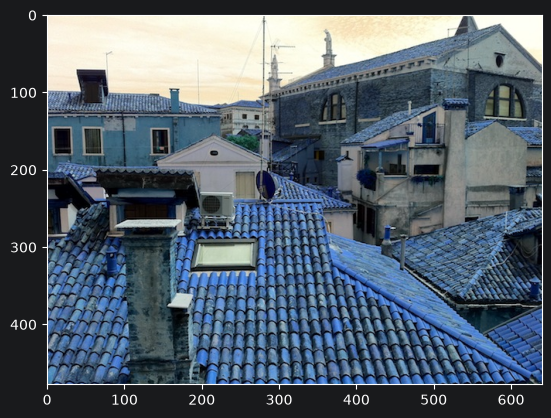

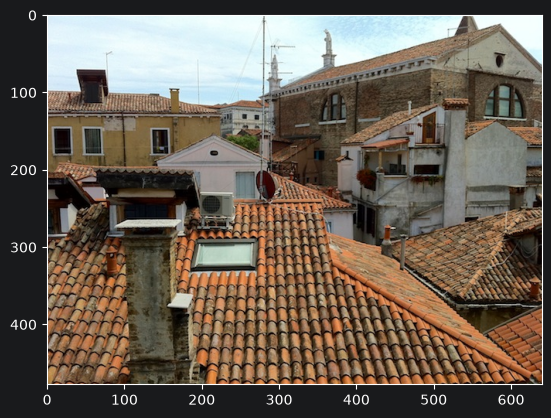

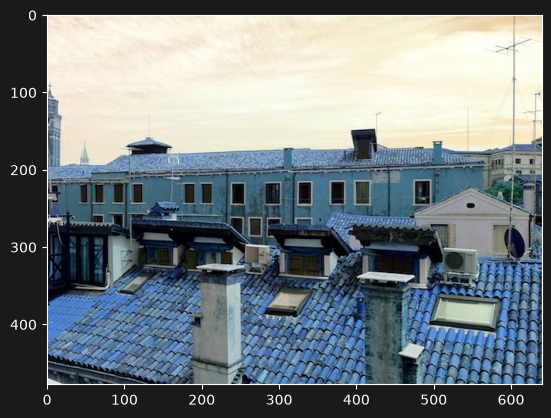

In [2]:
img1 = cv2.imread('../../data/test_images/roofs1.jpg')
img1b = imageio.imread('../../data/test_images/roofs1.jpg')
img2 = cv2.imread('../../data/test_images/roofs2.jpg')

plt.imshow(img1)
plt.show()
plt.imshow(img1b)
plt.show()
plt.imshow(img2)
plt.show()

Yes there is a difference. img1 is read with cv2.imread in BGR order, so plt.imshow shows the colors wrong (red and blue swapped). img1b is read with imageio.imread in RGB order, so it is shown correctly.

## Conversion from BGR to RGB
1. Define a function called *getRGB* which has one parameter *img* and a return value *rgbImg*
2. Assign to the variable *rgbImg* the RGB image generated from the BGR image (use *cv2.cvtColor*, with the appropriate parameters; Hint: cv2.COLOR_BGR2RGB)

In [3]:
def getRGB(img):
    rgbImg = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return rgbImg

## Conversion from BGR to grayscale
1. Define a function called *getGray* which has one parameter *img* and a return value *grayImg*
2. Assign to the variable *grayImg* the grayscale image generated from the BGR image (use *cv2.cvtColor*, with the appropriate parameters; Hint: cv2.COLOR_BGR2GRAY)

In [4]:
def getGray(img):
    grayImg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return grayImg

## Plotting all versions 
1. Call the function *getRGB* with *img1* as parameter and store the return value into a variable called *img1RGB* 
2. Call the function *getRGB* with *img2* as parameter and store the return value into a variable called *img2RGB* 
3. Call the function *getGray* with *img1* as parameter and store the return value into a variable called *img1Gray* 
4. Call the function *getGray* with *img2* as parameter and store the return value into a variable called *img2Gray*
5. Plot the variable *img1* (use *plt.imshow*, set the *cmap* parameter accordingly)
6. Plot the variable *img1RGB* (use *plt.imshow*, set the *cmap* parameter accordingly)
7. Plot the variable *img1Gray* (use *plt.imshow*, set the *cmap* parameter accordingly)

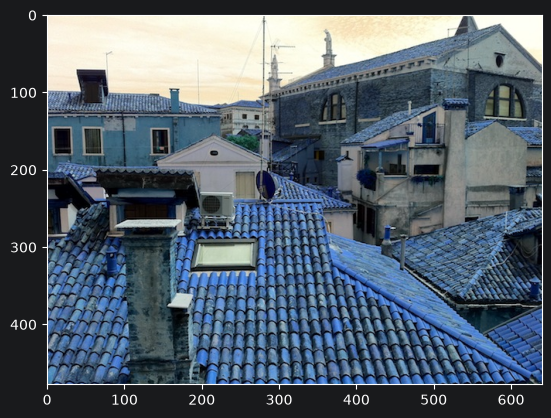

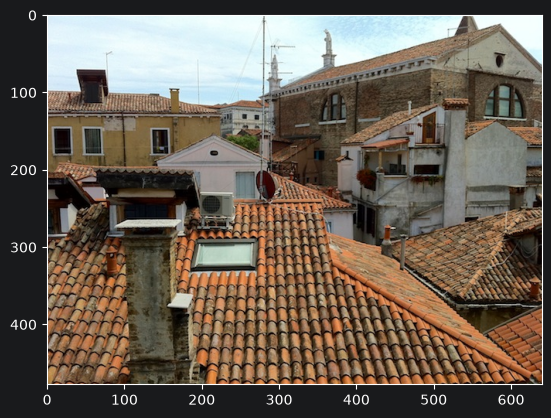

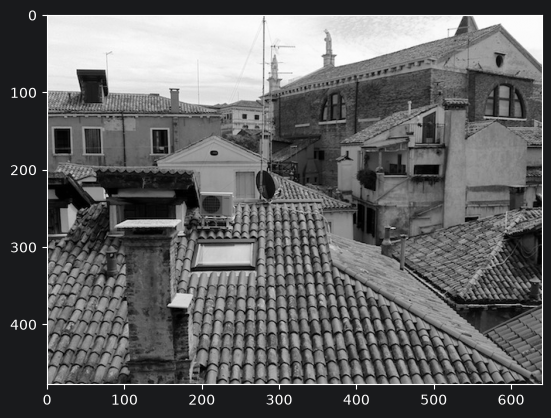

In [5]:
img1RGB = getRGB(img1)
img2RGB = getRGB(img2)
img1Gray = getGray(img1)
img2Gray = getGray(img2)

plt.imshow(img1)
plt.show()
plt.imshow(img1RGB)
plt.show()
plt.imshow(img1Gray, cmap='gray')
plt.show()

# Exercise 2:
## Generating ORB Features
1. Define a function called *getORB* with one parameter *img* and two return values *kp* and *desc*
2. In *getORB* call the function *cv2.ORB_create()* to generate an object of the ORB class and save it into a variable called *orb*
3. In the next step call the function *orb.detectAndCompute(img, None)* and save the return values into the variables *kp* and *desc*

In [6]:
def getORB(img):
    orb = cv2.ORB_create()
    kp, desc = orb.detectAndCompute(img, None)
    return kp, desc

## Visualizing ORB Features (1)
1. Define a function called *showORB* with two parameters *img* and *kp* and no return values
2. Create a new figure with the figsize=(20,10) (use function *plt.figure()*)
3. You will have to call the function *cv2.drawKeypoints* with following paramters: *img, kp, img.copy(), color=(0,255,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS*
4. Here you do not have a regular return value, but plot the return value instead(use *plt.imshow* and *plt.show*)

In [7]:
def showORB(img, kp):
    plt.figure(figsize=(20,10))
    out = cv2.drawKeypoints(img, kp, img.copy(), color=(0,255,0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.imshow(out)
    plt.show()

## Visualizing ORB Features (2)

1. Call the function *getORB* with *img1Gray* and store the return values into *kp1*, and *desc1*
2. Call the function *getORB* with *img2Gray* and store the return values into *kp2*, and *desc2*
3. Call the function *showORB* with *img1Gray* and *kp1* as parameters
4. Call the function *showORB* with *img2Gray* and *kp2* as parameters

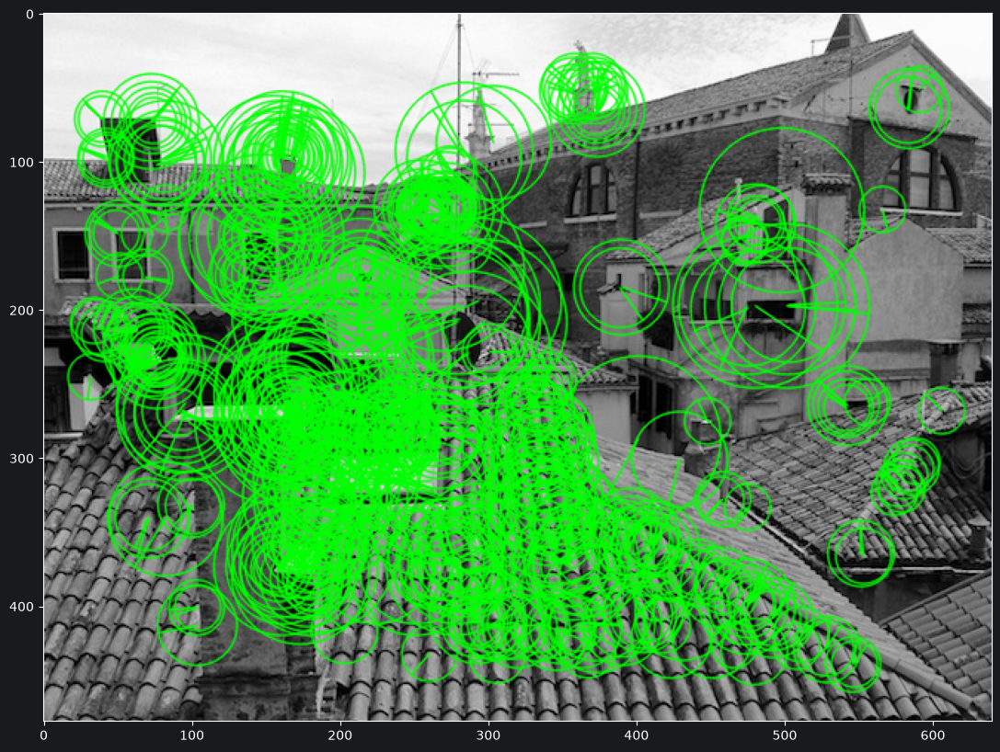

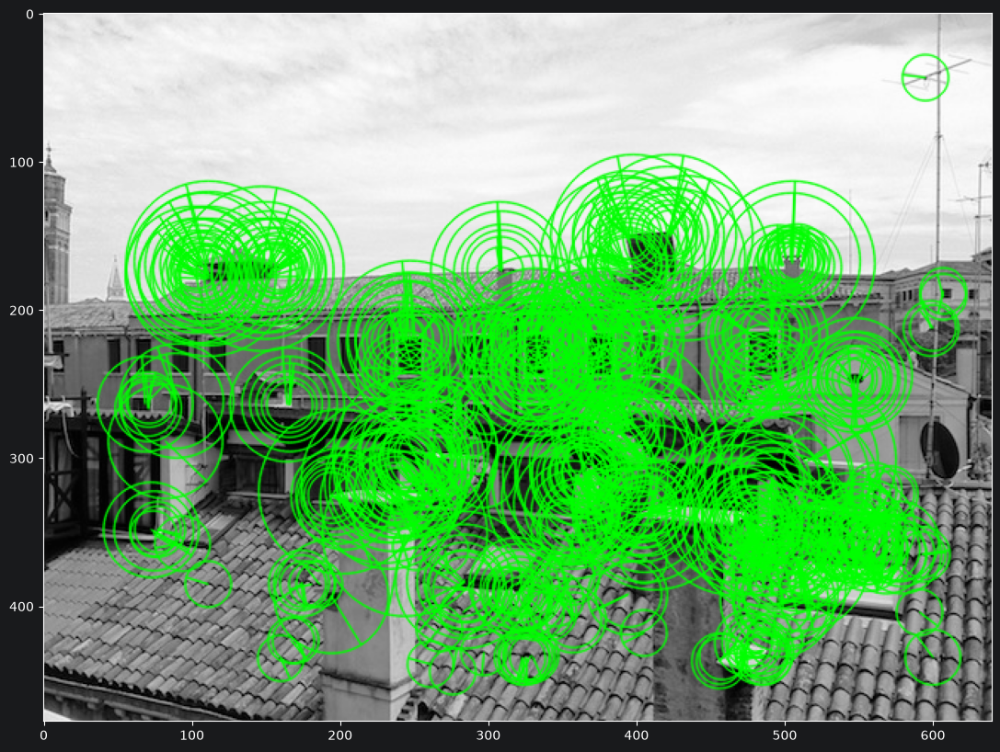

In [8]:
kp1, desc1 = getORB(img1Gray)
kp2, desc2 = getORB(img2Gray)
showORB(img1Gray, kp1)
showORB(img2Gray, kp2)

# Exercise 3:
## Feature Matching (1)
1. First, create a BFMatcher object (use *cv2.BFMatcher*) with distance measurement *cv2.NORM_HAMMING* and *crossCheck* set to *True*
2. Save the object into a variable called *bf*
3. Call the function *bf.match* with the descriptor variables *desc1* and *desc2* to get the best matches in the two images. 
4. Save the result in a variable called *matches*.
5. Define a functon called *getKey* which takes one parameter *x* and returns *x.distance*. You will need this function for sorting the matches in ascending order by distance. 
6. Call the function *sorted* and provide as parameters the variable *matches* and for *key = getKey* (this is the function we defined in the previous step)
7. Save the result in a variable called *sortedMatches*
8. Next, program a for loop with the loop variable *k* being 10, 20, 40, 60, 80
    1. In each iteration create a new figure with a *figsize =(20,10)* (use function *plt.figure()*)
    2. Call the function *cv2.drawMatches* In the for loop and provide *img1Gray*,*kp1*,*img2Gray*,*kp2*,*sortedMatches[:k]*, img2.copy(), flags=2 as parameters.
    3. In each iteration output the image, which is returned by the function *cv2.drawMatches* (use function *plt.imshow()* and *plt.show()*).
    
9. What can we observe? Are the ORB Features correctly matched?

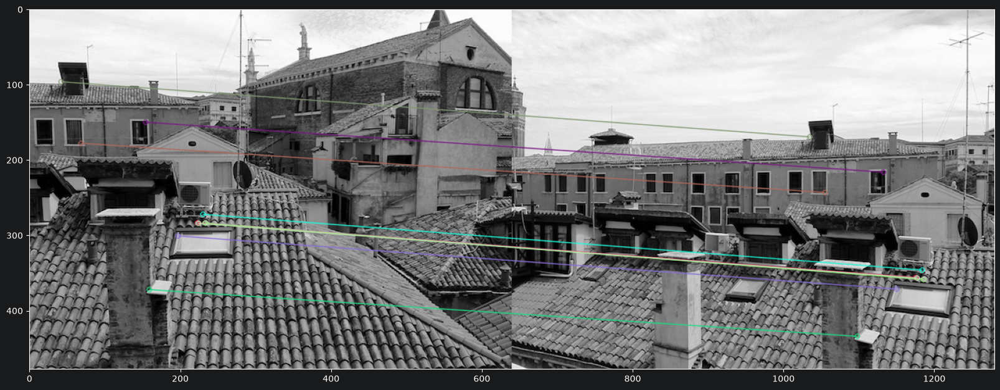

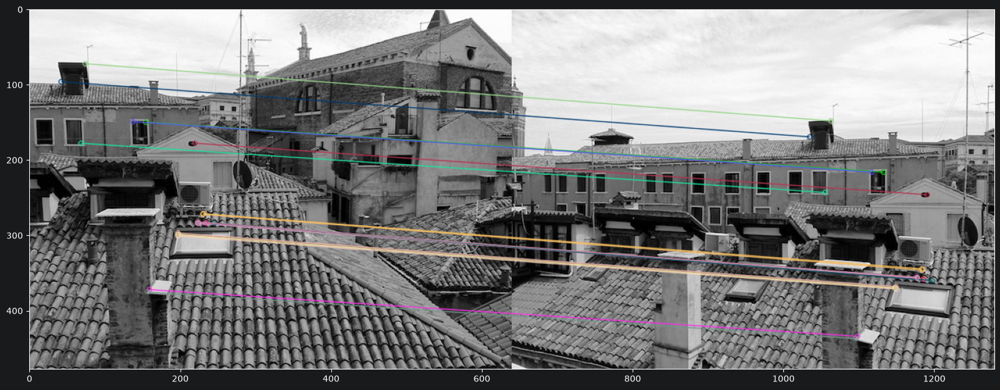

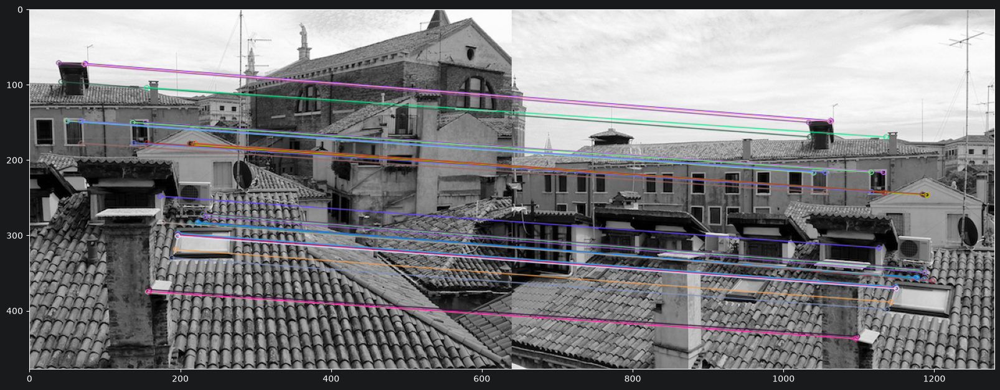

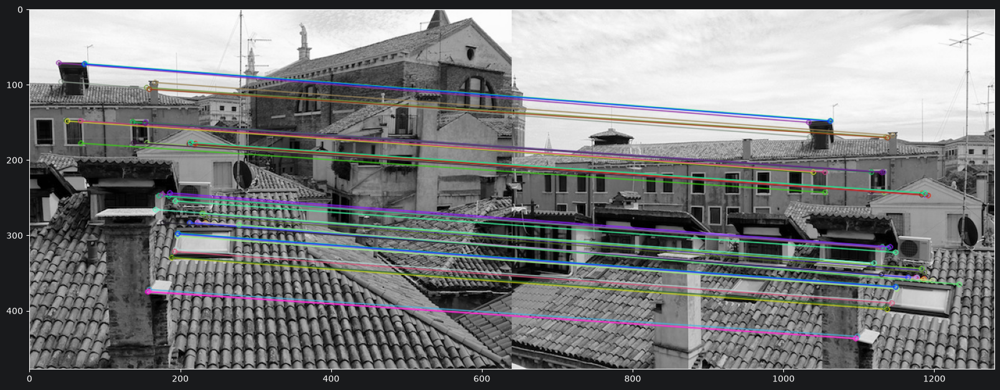

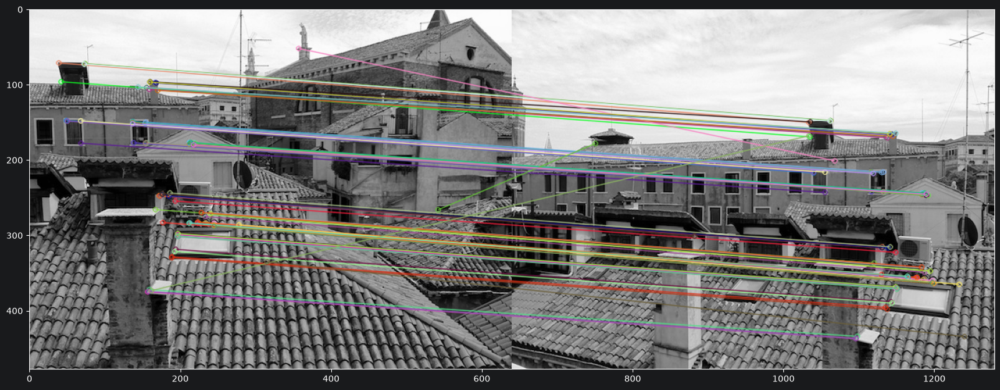

In [9]:
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(desc1, desc2)

def getKey(x):
    return x.distance

sortedMatches = sorted(matches, key=getKey)

for k in [10, 20, 40, 60, 80]:
    plt.figure(figsize=(20,10))
    out = cv2.drawMatches(img1Gray, kp1, img2Gray, kp2, sortedMatches[:k], img2.copy(), flags=2)
    plt.imshow(out)
    plt.show()

The two images show the same scene from a different viewpoint. The matches with the smallest distance (small k) are mostly correct. As k grows more wrong matches appear.

## Feature Matching (2)

1. Read in the provided image roofs3.jpg and store the return value into a variable called *img3* (use cv2.imread)
2. Generate the RGB and grayscale image (use *getRGB* and *getGray*)
3. Generate the ORB features and store the return values into variables called *kp3* and *desc3* (use *getORB*)
4. Copy the code from part 'Feature Matching (1)' and adapt it so that you compare img1 and img3
5. What can we observe? Are the ORB Features correctly matched?

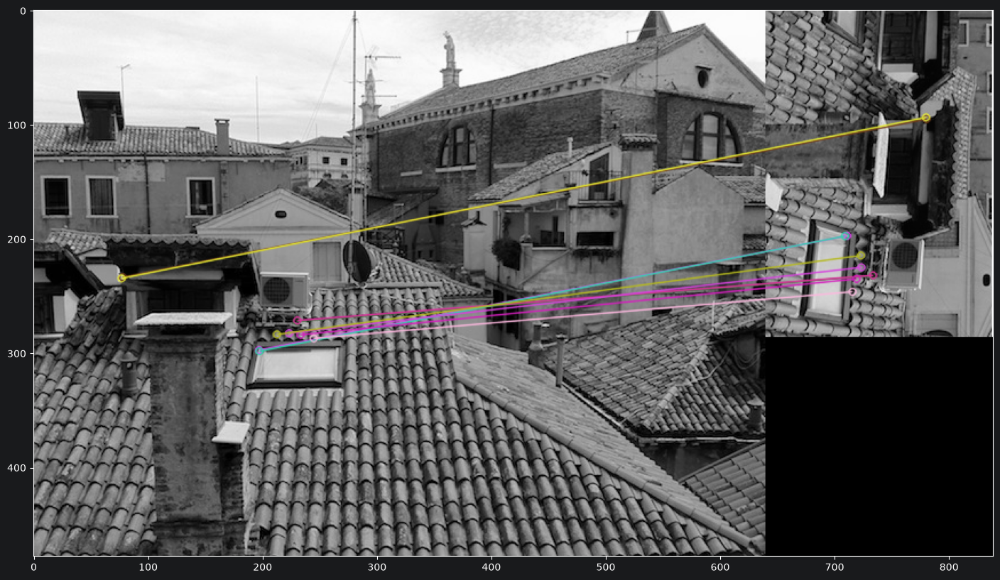

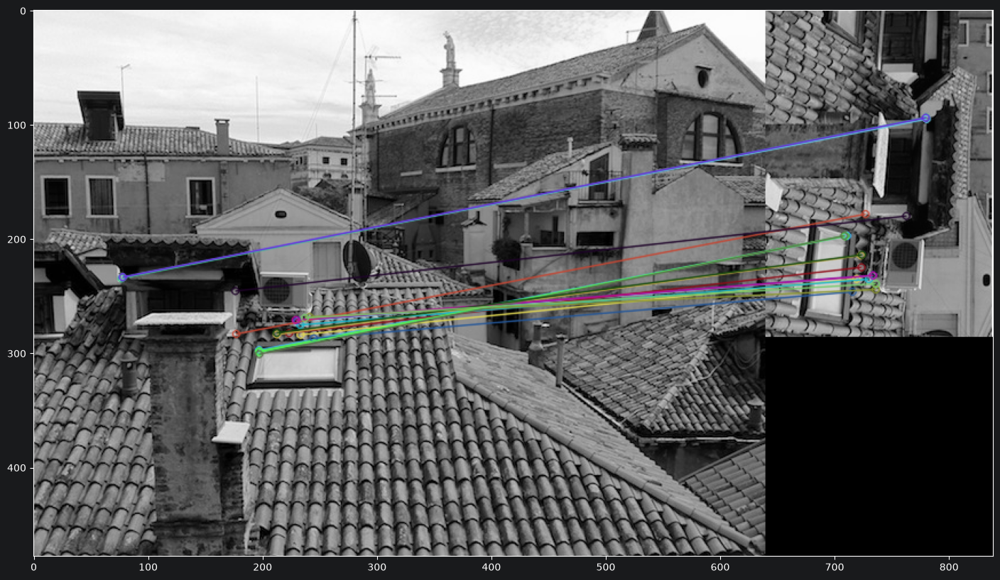

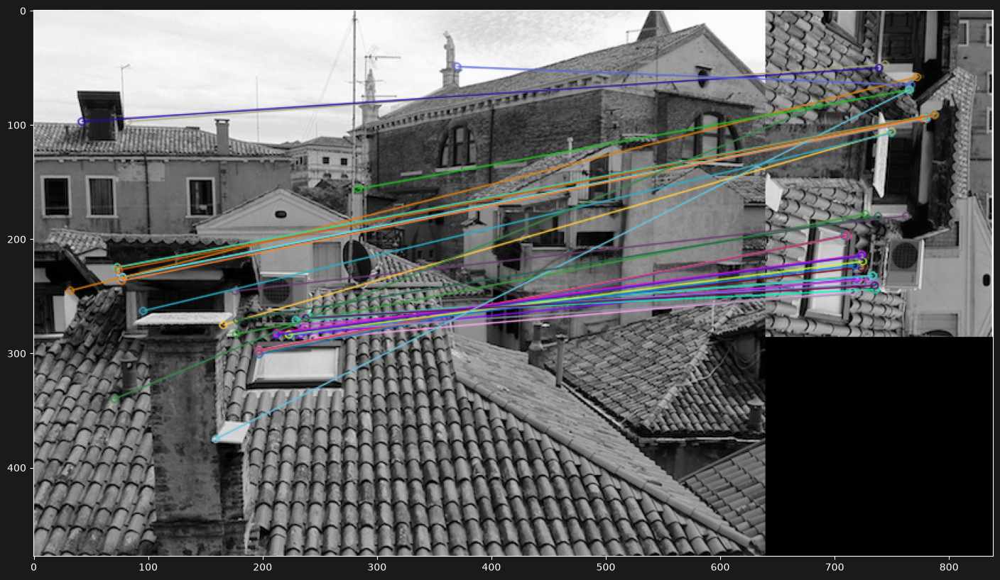

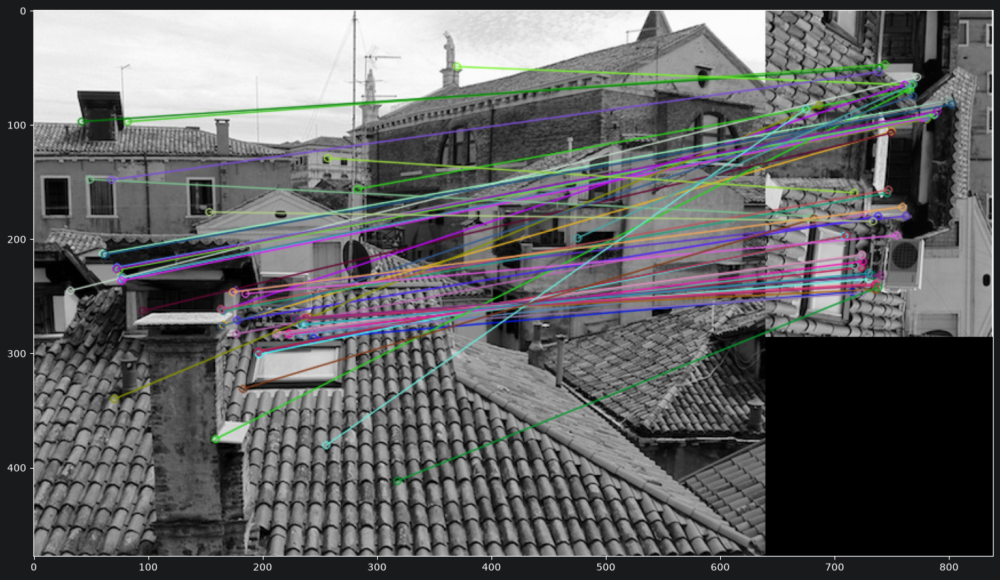

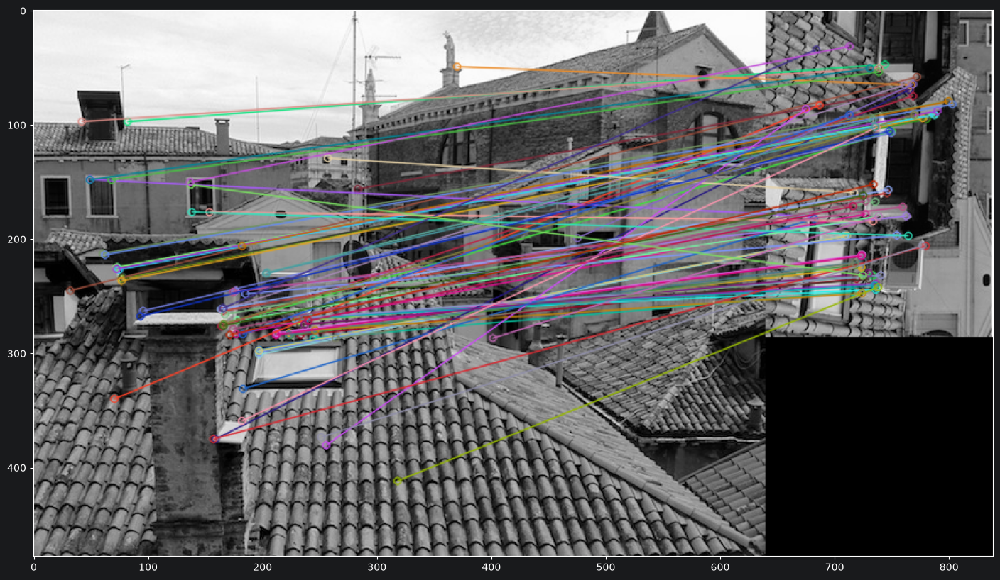

In [10]:
img3 = cv2.imread('../../data/test_images/roofs3.jpg')
img3RGB = getRGB(img3)
img3Gray = getGray(img3)
kp3, desc3 = getORB(img3Gray)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(desc1, desc3)
sortedMatches = sorted(matches, key=getKey)

for k in [10, 20, 40, 60, 80]:
    plt.figure(figsize=(20,10))
    out = cv2.drawMatches(img1Gray, kp1, img3Gray, kp3, sortedMatches[:k], img3.copy(), flags=2)
    plt.imshow(out)
    plt.show()

img1 and img3 again show the same kind of scene, so many features are matched correctly, mainly for small k.

## Feature Matching (3)
1. Read in the provided image karl.jpg and store the return value into a variable called *img3* (use cv2.imread)
2. Generate the RGB and grayscale image (use *getRGB* and *getGray*)
3. Generate the ORB features and store the return values into variables called *kp3* and *desc3* (use *getORB*)
4. Copy the code from part 'Feature Matching (1)' and adapt it so that you compare img1 and img3
5. What can we observe? Are the ORB Features correctly matched?

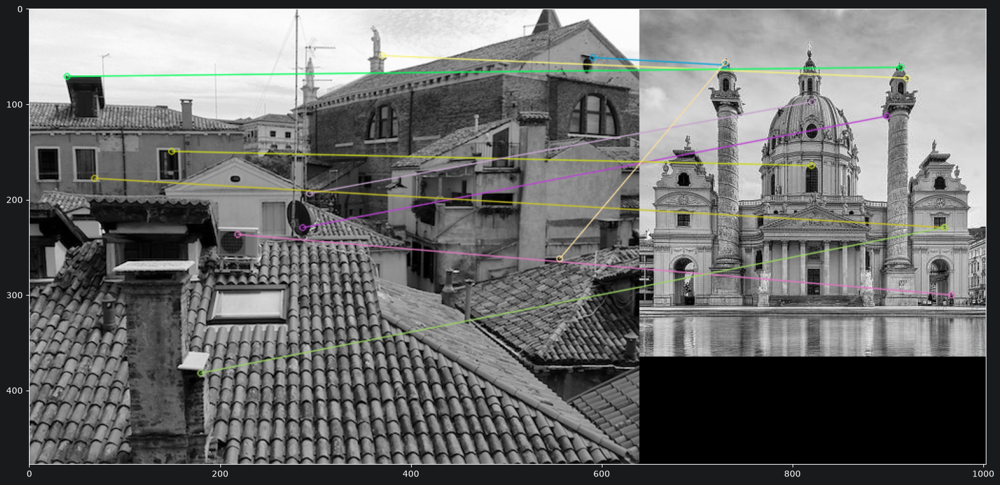

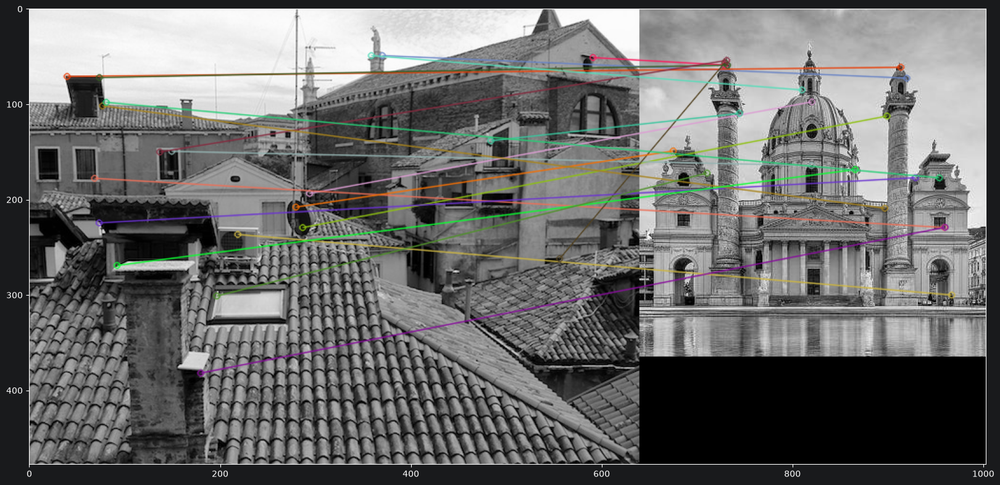

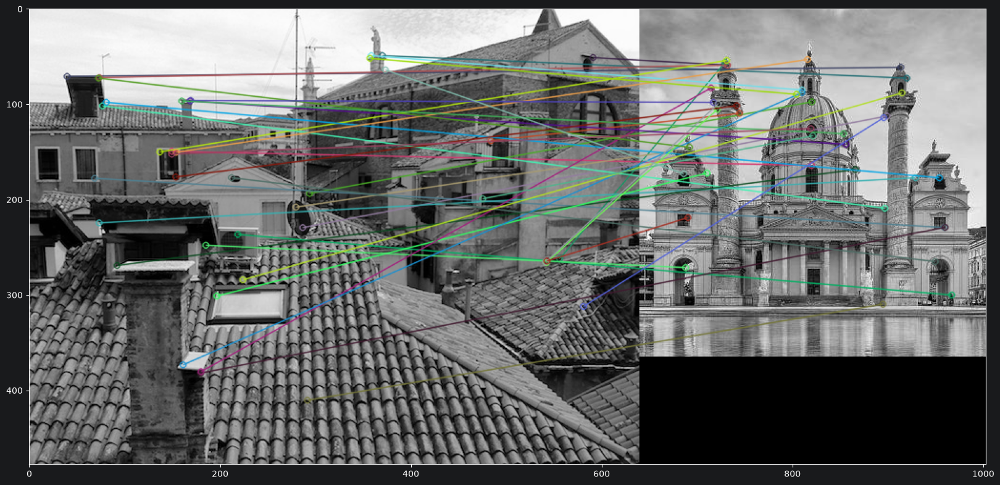

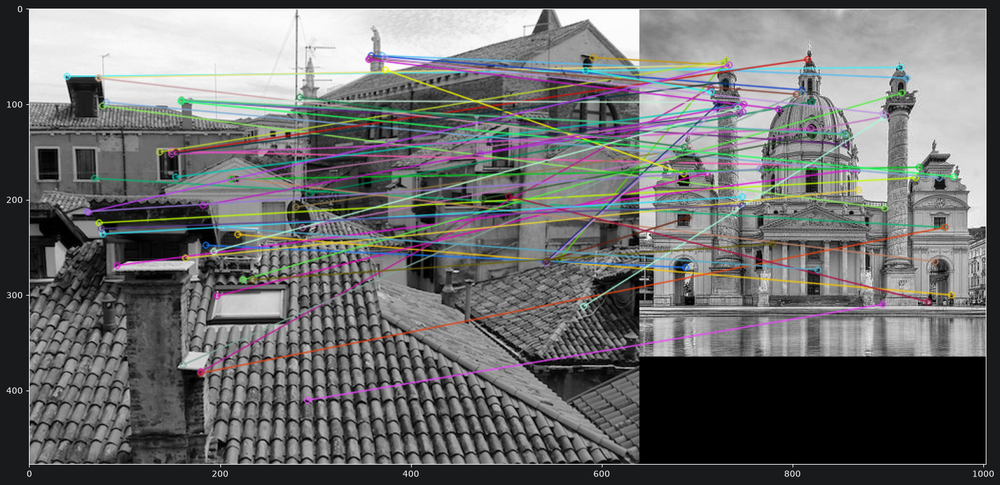

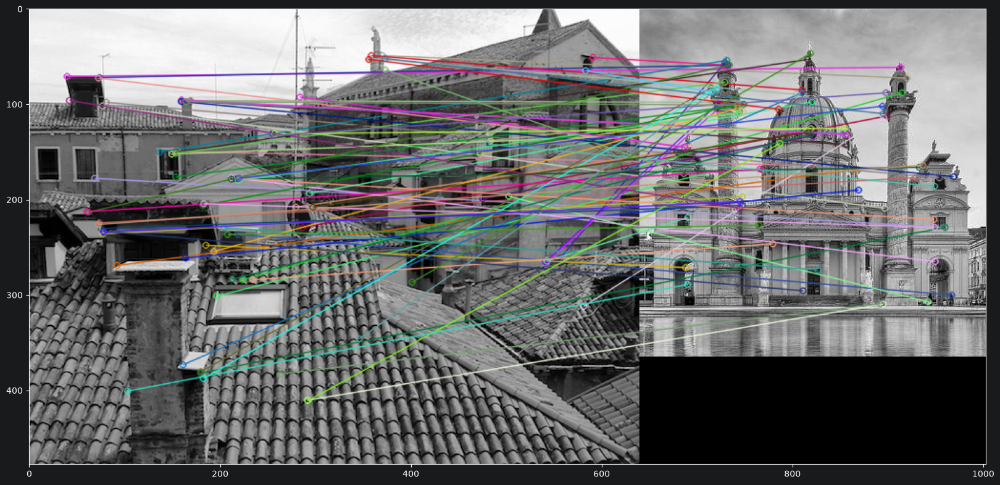

In [11]:
img3 = cv2.imread('../../data/test_images/karl.jpg')
img3RGB = getRGB(img3)
img3Gray = getGray(img3)
kp3, desc3 = getORB(img3Gray)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(desc1, desc3)
sortedMatches = sorted(matches, key=getKey)

for k in [10, 20, 40, 60, 80]:
    plt.figure(figsize=(20,10))
    out = cv2.drawMatches(img1Gray, kp1, img3Gray, kp3, sortedMatches[:k], img3.copy(), flags=2)
    plt.imshow(out)
    plt.show()

karl.jpg is a completely different image with no common content, so the matches are wrong and meaningless.